# Analysis for the paper

*Reliable Financial LLMs through Policy-as-Code Runtime Controls*.

This notebook turns the generated memos into every number, table and figure of the paper. It runs end to end on whatever data exists, so it can be re-executed as generations and labels arrive:

| Input | Produced by |
|---|---|
| `data/generated/{C0,C1}/<model>/` | `src/run_models_tmux.sh` → `src/run_c0_model.py` |
| `data/generated/{C2,C3}/<model>/` + `policy_audit.jsonl` | `src/policy_engine.py` (executes `policies/policies_v1.yaml`) |
| `data/annotations/judge_labels.csv` | `src/judge_claims.py` (LLM judge) |
| `data/annotations/human_labels.csv` | human annotation of `annotation_sample_v1.csv` (exported below) |

**Outputs:** `analysis/figures/*.pdf` (vector, fonts embedded, sized for ACM `sigconf`: 3.33 in column / 7.0 in text width), `analysis/figures/*.png` (previews), `analysis/tables/*.tex`, `analysis/tables/*.csv`, and `analysis/paper_numbers.md` (sentences with the numbers filled in).

**Label source matters.** Error labels come from a panel of three LLM judges from families disjoint from the generators (majority vote; §9), else a single LLM judge, else human annotation, else an *automatic proxy*. No human validation has been done: the paper must say that labels are LLM-based and rely on cross-judge agreement and robustness (§9) instead. The proxy uses the same kind of signals as the policies, so with proxy labels the runtime controls look perfect by construction: those figures validate the pipeline, not the paper's claims. Every figure is stamped with its label source.

Headless run: `MPLBACKEND=Agg python analysis/run_notebook.py analysis/paper_analysis.ipynb`

## Claims map

Each figure/table exists to support (or refute) one claim. Wording follows proposal §1.3 / §7.2: replace qualitative words with the observed numbers from `paper_numbers.md`, and never claim more than the experiment shows.

| # | Claim the paper can make (template) | RQ / H | Evidence | Supported if | If not supported (§7.2 pivot) |
|---|---|---|---|---|---|
| K1 | Prompt-only safeguards do not make LLMs abstain: models almost never self-report insufficient evidence, even when instructed to, while a sizeable share of their claims have material errors. | H3 | Fig. 3 | C1 self-flag rate ≪ material-error rate for every model | Report that prompting *does* elicit abstention; P3 then carries the benefit |
| K2 | Runtime Policy-as-Code controls reduce the severe errors that reach the analyst relative to both the baseline and prompt-only safeguards. | RQ1 / H1 | Fig. 2a, Tab. 2 | paired bootstrap CI of (C2 − C1) severe errors/memo excludes 0 | "Limits of runtime guardrails": where and why they fail (Fig. 4) |
| K3 | The reduction has an explicit, tunable cost: withheld claims (false blocks) and human escalations, with negligible latency. | RQ2 | Fig. 2c, Tab. 2 | frontier is monotone; policy engine ms ≪ generation s | Trade-off framing: report operating points only |
| K4 | Controls are complementary: each policy catches error types the others miss, and removing any one increases leakage. | RQ3 / H2 | Fig. 2b, Fig. 4 | every leave-one-out Δ > 0 with CI excluding 0 | Name the redundant policy; simplify the policy set |
| K5 | Most of the benefit comes from a small subset of policies. | H4 | Fig. 2c | a ≤2-policy subset on the frontier reaches ≥80% of the full reduction | All four are needed (strengthens K4) |
| K6 | Every release/block/escalate decision is reproducible from the audit log. | RQ4 | Tab. 2, audit replay | replay reproduces 100% of logged decisions | Report the non-reproducible share and cause |
| K7 | The reduction does not depend on which LLM labels the errors. | validity | Fig. 6, Tab. 3 | C2 − C1 CI excludes 0 under every judge | Report the judge(s) under which it fails and why |
| K8 | Under explicit pressure, prompt-only safeguards leak investment/credit recommendations; P4 (frozen before the test) removes most of them. | RQ1 / §4.4 | Fig. 7, Tab. 4 | S1 compliance > 0 and S1+P4 well below S1 | Report P4 recall honestly; misses motivate a versioned P4 v2 evaluated on held-out requests |

**GO / NO-GO (proposal §7.2)** is evaluated automatically at the end of the notebook.

## 0. Setup

In [1]:
import sys, json, re, textwrap, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "evaluation.py").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import policy_engine as pe
import evaluation as ev

FIG_DIR = PROJECT_ROOT / "analysis" / "figures"
TABLE_DIR = PROJECT_ROOT / "analysis" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

N_BOOT = 2000
SOURCE_CONDITION = "C1"     # C2/C3 = the C1 generator + runtime policies
LABEL_SOURCE = "auto"       # auto (panel if present) | panel | judge | judge:<name> | human | proxy
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)

In [2]:
# ---- ACM sigconf geometry and figure style --------------------------------
COLUMN_W = 3.33   # \columnwidth, inches
TEXT_W = 7.0      # \textwidth, inches

INK = "#0b0b0b"        # primary text
INK_2 = "#52514e"      # secondary text, axes
GRID = "#e4e2dc"       # hairline grid
MUTED = "#b9b7b0"      # de-emphasized marks

# Categorical slots 1-3 (validated all-pairs: CVD dE 9.2, normal-vision dE 24.0).
# Color follows the model everywhere in the paper.
MODEL_COLOR = {
    "qwen35_27b": "#2a78d6",
    "llama31_8b_instruct": "#eb6834",
    "mistral7b_instruct": "#1baf7a",
}
MODEL_NAME = {
    "qwen35_27b": "Qwen3.5-27B",
    "llama31_8b_instruct": "Llama-3.1-8B",
    "mistral7b_instruct": "Mistral-7B",
}
# Conditions are an ordered progression of controls: one-hue ordinal ramp
# (validated --ordinal; light end 2.06:1 on the surface).
CONDITION_COLOR = {"C0": "#86b6ef", "C1": "#5598e7", "C2": "#256abf", "C3": "#104281"}
CONDITION_NAME = {
    "C0": "C0 baseline",
    "C1": "C1 prompt-only",
    "C2": "C2 runtime policies",
    "C3": "C3 + human review",
}

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans", "Nimbus Sans", "DejaVu Sans"],
    "font.size": 7,
    "axes.titlesize": 7.5,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 7,
    "axes.labelcolor": INK,
    "axes.edgecolor": INK_2,
    "axes.linewidth": 0.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID,
    "grid.linewidth": 0.5,
    "grid.linestyle": "-",
    "axes.axisbelow": True,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "legend.fontsize": 6.5,
    "legend.frameon": False,
    "legend.handlelength": 1.2,
    "lines.linewidth": 1.2,
    "errorbar.capsize": 0,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42,     # embed TrueType: required by ACM
    "ps.fonttype": 42,
})


def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")
    print(f"saved analysis/figures/{name}.pdf")


def stamp_labels(fig):
    """Every figure states where its error labels came from."""
    text = {
        "proxy": "labels: automatic proxy (pipeline check, not evidence)",
        "panel": f"labels: majority of {len(ev.available_judges(ev.PANEL))} LLM judges",
        "judge": "labels: LLM judge (Qwen3.5-27B)",
        "human": "labels: human annotation (weighted sample)",
    }.get(LABEL_SOURCE_USED, f"labels: {LABEL_SOURCE_USED}")
    # Place it just below everything already drawn (tick labels, xlabels).
    fig.canvas.draw()
    bottom = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    fig.text(0.995, bottom - 0.01, text, ha="right", va="top", fontsize=5,
             color=INK_2 if LABEL_SOURCE_USED != "proxy" else "#c0392b")


def pct(x, digits=1):
    return "n/a" if x is None or np.isnan(x) else f"{100 * x:.{digits}f}%"


def ordered_models(frame):
    return [m for m in MODEL_COLOR if m in set(frame["model"])]

## 1. Data

Generated memos (C0/C1), one row per claim, plus every runtime policy signal computed once per claim, so ablations and threshold sweeps need no re-execution.

In [3]:
policy_set = pe.load_policy_set()
memos, claims = ev.load_memos(("C0", "C1"))
memos, claims = ev.add_policy_signals(memos, claims, policy_set)
labels, LABEL_SOURCE_USED = ev.load_labels(memos, claims, policy_set, LABEL_SOURCE)
MODELS = ordered_models(claims)

coverage = (
    memos.groupby(["model", "condition"])
    .agg(memos=("ticker", "size"), parsed=("parse_ok", "mean"), claims_per_memo=("n_claims", "mean"),
         out_tokens=("output_tokens", "mean"), gen_s=("gen_latency_s", "mean"))
    .round(2)
)
print(f"label source: {LABEL_SOURCE_USED}   policy set {policy_set['version']} sha256={policy_set['sha256'][:12]}")
print(f"{len(memos)} memos, {len(claims)} claims, models: {[MODEL_NAME[m] for m in MODELS]}")
coverage

label source: panel   policy set 1.0.0 sha256=d35f7eb4bdd7
582 memos, 7955 claims, models: ['Qwen3.5-27B', 'Llama-3.1-8B', 'Mistral-7B']


memos  parsed  claims_per_memo  out_tokens  gen_s
model               condition                                                   
llama31_8b_instruct C0            97    1.00            14.51     1226.38   0.59
                    C1            97    0.99            14.23     1195.26   0.81
mistral7b_instruct  C0            97    1.00            11.38     1325.64   0.88
                    C1            97    1.00            12.20     1317.89   0.95
qwen35_27b          C0            97    1.00            14.92     1335.45   6.19
                    C1            97    1.00            14.78     1311.69   6.51

In [4]:
# Label distribution per generation condition (weighted when labels are a sample)
lab = claims[["model", "condition"]].join(labels)
(lab.assign(w=lab["weight"])
    .pivot_table(index=["model", "condition"], columns="severity", values="w", aggfunc="sum", fill_value=0)
    .pipe(lambda t: t.div(t.sum(axis=1), axis=0))
    .round(3))

severity                          S0     S1     S2
model               condition                     
llama31_8b_instruct C0         0.898  0.061  0.041
                    C1         0.916  0.052  0.032
mistral7b_instruct  C0         0.933  0.039  0.028
                    C1         0.928  0.048  0.024
qwen35_27b          C0         0.988  0.010  0.003
                    C1         0.992  0.006  0.002

## 2. Table 1 — the policy set as code

Generated from `policies/policies_v1.yaml`, so the paper's table cannot drift from what was executed.

In [5]:
def latex_escape(s):
    return (str(s).replace("\\", r"\textbackslash{}").replace("_", r"\_").replace("%", r"\%")
            .replace("&", r"\&").replace("#", r"\#").replace("$", r"\$"))

rule_text = {
    "P1_GROUNDEDNESS": "cites evidence shown to the model; lexical support $\\geq$ {min_lexical_support}",
    "P2_NUMERIC_CONSISTENCY": "every number matches cited evidence (rel. tol. {relative_tolerance})",
    "P3_UNCERTAINTY": "self-flagged insufficiency, or claim year absent from cited evidence",
    "P4_DECISION_BOUNDARY": "{n_patterns} recommendation patterns (claim and memo)",
}
rows = []
for p in policy_set["policies"]:
    rule = dict(p["rule"])
    rule["n_patterns"] = len(rule.get("patterns", []))
    rows.append({
        "Policy": f"{ev.SHORT[p['policy_id']]} {p['policy_id'].split('_', 1)[1].replace('_', ' ').title()} (v{p['version']})",
        "Scope": p["scope"].replace("_", " "),
        "Rule": rule_text[p["policy_id"]].format(**rule),
        "Action on fail": p["action_on_fail"],
    })
table1 = pd.DataFrame(rows)

lines = [r"\begin{tabular}{@{}llp{0.42\linewidth}l@{}}", r"\toprule",
         " & ".join(rf"\textbf{{{c}}}" for c in table1.columns) + r" \\", r"\midrule"]
for _, r in table1.iterrows():
    cells = [latex_escape(r["Policy"]), latex_escape(r["Scope"]), r["Rule"].replace("%", r"\%"), r"\texttt{" + r["Action on fail"] + "}"]
    lines.append(" & ".join(cells) + r" \\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLE_DIR / "table1_policies.tex").write_text("\n".join(lines))
table1

,Policy,Scope,Rule,Action on fail
0,P1 Groundedness (v1),all claims,cites evidence shown to the model; lexical sup...,BLOCK
1,P2 Numeric Consistency (v1),numeric claims,every number matches cited evidence (rel. tol....,ESCALATE
2,P3 Uncertainty (v1),all claims,"self-flagged insufficiency, or claim year abse...",ESCALATE
3,P4 Decision Boundary (v1),all claims and memo,9 recommendation patterns (claim and memo),BLOCK


## 3. Scenario metrics with company-level cluster bootstrap

All scenarios reuse the same resampled companies, so C2 − C1 differences are paired. Metrics follow proposal §5.1–5.3; RWL and SEPR are 1 by definition for C0/C1 (no control), so the cross-condition comparison uses **severe errors reaching the user per memo**.

In [6]:
def sums_for(scenario, enabled=pe.POLICY_IDS, p1_threshold=None):
    frame, memo_frame = ev.scenario_frame(claims, labels, memos, scenario, SOURCE_CONDITION, enabled, p1_threshold)
    return ev.per_ticker_sums(frame, memo_frame)

scenario_sums = {s: sums_for(s) for s in ("C0", "C1", "C2", "C3")}

# Leave-one-out ablations of the full C2 policy set
for policy in pe.POLICY_IDS:
    keep = tuple(p for p in pe.POLICY_IDS if p != policy)
    scenario_sums[f"C2 -{ev.SHORT[policy]}"] = sums_for("C2", keep)

boot = ev.bootstrap(scenario_sums, n_boot=N_BOOT)
point = boot.pivot_table(index=["scenario", "model"], columns="metric", values="point")
point.to_csv(TABLE_DIR / "metrics_by_scenario.csv")
point.loc[(["C0", "C1", "C2", "C3"], "all"), ["severe_per_memo", "sepr", "rwl", "unsupported_rate",
    "numeric_error_rate", "evidence_coverage", "false_block_rate", "withheld_share", "escalation_rate"]].round(3)

,metric,severe_per_memo,sepr,rwl,unsupported_rate,numeric_error_rate,evidence_coverage,false_block_rate,withheld_share,escalation_rate
scenario,model,,,,,,,,,
C0,all,0.320,1.000,1.000,0.017,0.043,0.985,0.000,0.000,0.000
C1,all,0.258,1.000,1.000,0.015,0.046,0.986,0.000,0.000,0.000
C2,all,0.127,0.493,0.460,0.005,0.032,1.000,0.141,0.148,0.034
C3,all,0.127,0.493,0.477,0.005,0.030,1.000,0.110,0.148,0.034


## 4. Table 2 — main results

One row per model × condition. `table2_main.tex` is ready for a `table*` environment.

In [7]:
TABLE2_METRICS = [
    ("severe_per_memo", "Severe/memo", "num"),
    ("sepr", "SEPR", "pct"),
    ("rwl", "RWL", "pct"),
    ("unsupported_rate", "Unsupp.", "pct"),
    ("numeric_error_rate", "Num. err.", "pct"),
    ("evidence_coverage", "Evid. cov.", "pct"),
    ("false_block_rate", "False block", "pct"),
    ("escalation_rate", "Escal.", "pct"),
    ("engine_ms_per_memo", "Policy ms", "ms"),
]

def fmt_cell(row, fmt):
    v, lo, hi = row["point"], row["lo"], row["hi"]
    if np.isnan(v):
        return "--"
    if fmt == "pct":
        return f"{100*v:.1f}"
    if fmt == "ms":
        return f"{v:.1f}"
    return f"{v:.2f} {{\\scriptsize[{lo:.2f},{hi:.2f}]}}"

records = []
for model in [*MODELS, "all"]:
    for scenario in ("C0", "C1", "C2", "C3"):
        sel = boot[(boot["scenario"] == scenario) & (boot["model"] == model)].set_index("metric")
        rec = {"Model": MODEL_NAME.get(model, "All models"), "Cond.": scenario}
        for key, name, fmt in TABLE2_METRICS:
            rec[name] = fmt_cell(sel.loc[key], fmt)
        records.append(rec)
table2 = pd.DataFrame(records)

lines = [r"\begin{tabular}{@{}ll" + "r" * len(TABLE2_METRICS) + r"@{}}", r"\toprule",
         " & ".join(rf"\textbf{{{c}}}" for c in table2.columns) + r" \\"]
for i, r in table2.iterrows():
    if i % 4 == 0:
        lines.append(r"\midrule")
    model_cell = r["Model"] if i % 4 == 0 else ""
    lines.append(" & ".join([model_cell] + [str(r[c]) for c in table2.columns[1:]]) + r" \\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLE_DIR / "table2_main.tex").write_text("\n".join(lines))
table2.to_csv(TABLE_DIR / "table2_main.csv", index=False)
table2

,Model,Cond.,Severe/memo,SEPR,RWL,Unsupp.,Num. err.,Evid. cov.,False block,Escal.,Policy ms
0,Qwen3.5-27B,C0,"0.04 {\scriptsize[0.00,0.10]}",100.0,100.0,0.1,1.2,99.9,0.0,0.0,3.8
1,Qwen3.5-27B,C1,"0.03 {\scriptsize[0.00,0.07]}",100.0,100.0,0.0,0.7,100.0,0.0,0.0,3.6
2,Qwen3.5-27B,C2,"0.03 {\scriptsize[0.00,0.07]}",100.0,100.0,0.0,0.7,100.0,3.3,2.6,3.6
3,Qwen3.5-27B,C3,"0.03 {\scriptsize[0.00,0.07]}",100.0,100.0,0.0,0.7,100.0,0.6,2.6,3.6
4,Llama-3.1-8B,C0,"0.60 {\scriptsize[0.38,0.87]}",100.0,100.0,3.3,6.9,99.8,0.0,0.0,3.6
5,Llama-3.1-8B,C1,"0.45 {\scriptsize[0.28,0.65]}",100.0,100.0,2.7,9.0,99.8,0.0,0.0,3.8
6,Llama-3.1-8B,C2,"0.19 {\scriptsize[0.09,0.30]}",40.9,41.2,0.7,5.9,100.0,14.9,5.3,3.8
7,Llama-3.1-8B,C3,"0.19 {\scriptsize[0.09,0.30]}",40.9,43.1,0.7,5.5,100.0,10.3,5.3,3.8
8,Mistral-7B,C0,"0.32 {\scriptsize[0.22,0.44]}",100.0,100.0,1.9,7.1,95.1,0.0,0.0,2.7
9,Mistral-7B,C1,"0.29 {\scriptsize[0.16,0.42]}",100.0,100.0,1.9,5.8,95.5,0.0,0.0,2.8


## 5. Figure 2 (double column) — the main result in three panels

* **(a) K2:** severe errors that reach the analyst per memo, by condition and model (95% cluster-bootstrap CI). C3 equals C2 here by construction (the reviewer drops escalated errors); its benefit is coverage, shown in Table 2.
* **(b) K4:** leave-one-out ablation — how many more severe errors reach the user per memo when one policy is removed from the full set.
* **(c) K3/K5:** risk–cost frontier over all 16 policy subsets (x: share of claims withheld from automatic release; y: severe errors per memo), plus the P1 threshold sweep.

saved analysis/figures/fig2_main_results.pdf


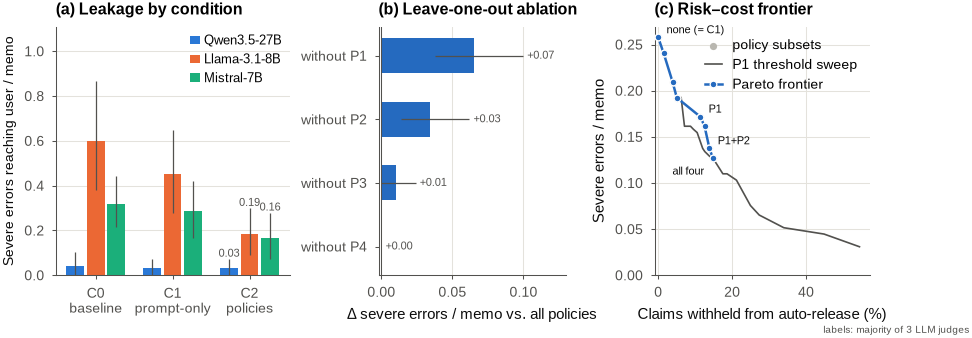

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(TEXT_W, 2.15), gridspec_kw={"width_ratios": [1.25, 1.0, 1.15], "wspace": 0.42})

# ---- (a) severe errors per memo by condition --------------------------------
ax = axes[0]
conds = ["C0", "C1", "C2"]
width = 0.8 / max(len(MODELS), 1)
for i, model in enumerate(MODELS):
    sel = boot[(boot["model"] == model) & (boot["metric"] == "severe_per_memo")].set_index("scenario")
    x = np.arange(len(conds)) + (i - (len(MODELS) - 1) / 2) * width
    y = sel.loc[conds, "point"].to_numpy()
    err = np.vstack([y - sel.loc[conds, "lo"].to_numpy(), sel.loc[conds, "hi"].to_numpy() - y])
    ax.bar(x, y, width * 0.86, color=MODEL_COLOR[model], label=MODEL_NAME[model], linewidth=0)
    ax.errorbar(x, y, yerr=np.clip(err, 0, None), fmt="none", ecolor=INK_2, elinewidth=0.6)
    ax.text(x[-1], sel.loc[conds[-1], "hi"], f"{y[-1]:.2f}", ha="center", va="bottom", fontsize=5.5, color=INK_2)
ax.set_xticks(range(len(conds)), ["C0\nbaseline", "C1\nprompt-only", "C2\npolicies"])
ax.set_ylabel("Severe errors reaching user / memo", fontsize=6.5)
ax.set_title("(a) Leakage by condition")
top = boot[(boot["metric"] == "severe_per_memo") & boot["model"].isin(MODELS) & boot["scenario"].isin(conds)]["hi"].max()
ax.set_ylim(0, (top if np.isfinite(top) and top > 0 else 1) * 1.28)
ax.legend(loc="upper right", ncols=1, fontsize=6, handlelength=0.8,
          handletextpad=0.3, borderaxespad=0.2)

# ---- (b) leave-one-out ablation --------------------------------------------
ax = axes[1]
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
names, deltas, los, his = [], [], [], []
for policy in pe.POLICY_IDS:
    d, lo, hi = ev.paired_difference(boot, "severe_per_memo", f"C2 -{ev.SHORT[policy]}", "C2")
    names.append(f"without {ev.SHORT[policy]}")
    deltas.append(d); los.append(lo); his.append(hi)
y = np.arange(len(names))[::-1]
deltas = np.array(deltas)
ax.barh(y, deltas, 0.55, color=CONDITION_COLOR["C2"], linewidth=0)
ax.errorbar(deltas, y, xerr=np.clip(np.vstack([deltas - los, np.array(his) - deltas]), 0, None),
            fmt="none", ecolor=INK_2, elinewidth=0.6)
ax.axvline(0, color=INK_2, linewidth=0.5)
ax.set_yticks(y, names)
ax.set_xlabel("Δ severe errors / memo vs. all policies")
ax.set_title("(b) Leave-one-out ablation")
span = max(np.nanmax(his), 1e-9)
for yi, d, hi in zip(y, deltas, his):
    ax.text(max(d, hi) + 0.03 * span, yi, f"{d:+.2f}", fontsize=5.5, color=INK_2, ha="left", va="center")
ax.set_xlim(left=min(0, np.nanmin(los)) - 0.02 * span, right=span * 1.3)

# ---- (c) risk-cost frontier -------------------------------------------------
ax = axes[2]
ax.grid(axis="x", visible=True)
points = []
for subset in ev.policy_subsets():
    r = ev.ratios(sums_for("C2", subset).sum())
    points.append({"subset": ev.subset_label(subset), "size": len(subset),
                   "x": float(r["withheld_share"]), "y": float(r["severe_per_memo"])})
pts = pd.DataFrame(points)
pts["frontier"] = [not ((pts["x"] <= r.x) & (pts["y"] <= r.y) & ((pts["x"] < r.x) | (pts["y"] < r.y))).any()
                   for r in pts.itertuples()]
front = pts[pts["frontier"]].sort_values("x")

sweep = []
for t in np.round(np.arange(0.0, 0.91, 0.05), 2):
    r = ev.ratios(sums_for("C2", pe.POLICY_IDS, p1_threshold=t).sum())
    sweep.append((float(r["withheld_share"]), float(r["severe_per_memo"]), t))
sweep = np.array(sweep)

ax.scatter(pts["x"] * 100, pts["y"], s=12, color=MUTED, linewidth=0, label="policy subsets", zorder=2)
ax.plot(sweep[:, 0] * 100, sweep[:, 1], color=INK_2, linewidth=0.8,
        label="P1 threshold sweep", zorder=3)
ax.plot(front["x"] * 100, front["y"], color=CONDITION_COLOR["C2"], linewidth=1.2, marker="o",
        markersize=3.2, markeredgecolor="white", markeredgewidth=0.6, label="Pareto frontier", zorder=4)
for r in front.itertuples():
    if r.subset in ("none", "P1", "P1+P2", "P1+P2+P3+P4"):
        name = {"none": "none (= C1)", "P1+P2+P3+P4": "all four"}.get(r.subset, r.subset)
        below = r.subset == "P1+P2+P3+P4"
        ax.annotate(name, (r.x * 100, r.y), textcoords="offset points",
                    xytext=(-4, -8) if below else (4, 2), ha="right" if below else "left",
                    fontsize=5.5, color=INK)
ax.set_xlabel("Claims withheld from auto-release (%)")
ax.set_ylabel("Severe errors / memo")
ax.set_title("(c) Risk–cost frontier")
ax.set_xlim(left=-1)
ax.set_ylim(bottom=0)
ax.legend(loc="upper right")

stamp_labels(fig)
save(fig, "fig2_main_results")
plt.show()
pareto_points, p1_sweep = pts, sweep

## 6. Figure 3 (single column) — prompt-only safeguards do not produce abstention (K1)

Per model and generation condition: share of claims the model itself flagged as `sufficient_evidence=false`, share flagged by the runtime controls (P1–P3), and share labeled as material errors (S2/S3). The gap between the first and the last marker is what prompt-only safeguards leave to chance.

saved analysis/figures/fig3_abstention_gap.pdf


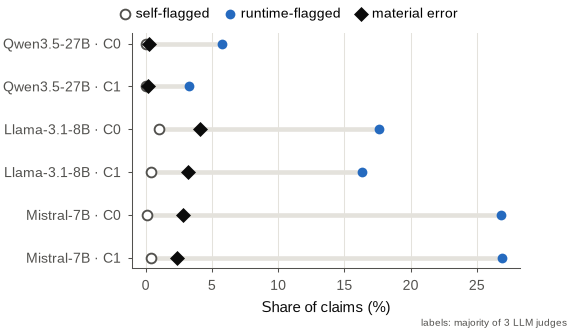

,row,self,runtime,error
0,Qwen3.5-27B · C0,0.000,0.057,0.003
1,Qwen3.5-27B · C1,0.000,0.033,0.002
2,Llama-3.1-8B · C0,0.010,0.176,0.041
3,Llama-3.1-8B · C1,0.004,0.163,0.032
4,Mistral-7B · C0,0.001,0.268,0.028
5,Mistral-7B · C1,0.004,0.269,0.024


In [9]:
rows = []
for model in MODELS:
    for condition in ("C0", "C1"):
        m = (claims["model"] == model) & (claims["condition"] == condition)
        w = labels.loc[m, "weight"]
        flagged = ~(claims.loc[m, "P1_pass"] & claims.loc[m, "P2_pass"] & claims.loc[m, "P3_pass"])
        rows.append({
            "row": f"{MODEL_NAME[model]} · {condition}",
            "self": claims.loc[m, "self_flagged"].mean(),
            "runtime": flagged.mean(),
            "error": np.average(labels.loc[m, "severity"].isin(ev.SEVERE), weights=w) if w.sum() > 0 else np.nan,
        })
abst = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(COLUMN_W, 0.42 + 0.27 * len(abst)))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
y = np.arange(len(abst))[::-1]
ax.hlines(y, abst["self"] * 100, abst[["runtime", "error"]].max(axis=1) * 100, color=GRID, linewidth=2.2, zorder=1)
ax.scatter(abst["self"] * 100, y, s=22, facecolor="white", edgecolor=INK_2, linewidth=0.9, label="self-flagged", zorder=3)
ax.scatter(abst["runtime"] * 100, y, s=22, color=CONDITION_COLOR["C2"], linewidth=0, label="runtime-flagged", zorder=3)
ax.scatter(abst["error"] * 100, y, s=26, marker="D", color=INK, linewidth=0, label="material error", zorder=4)
ax.set_yticks(y, abst["row"])
ax.set_xlabel("Share of claims (%)")
ax.set_xlim(left=-1)
ax.legend(loc="lower center", bbox_to_anchor=(0.4, 1.0), ncols=3, columnspacing=0.9, handletextpad=0.2)
stamp_labels(fig)
save(fig, "fig3_abstention_gap")
plt.show()
abst.round(3)

## 7. Figure 4 (single column) — what each control catches (K4)

Recall of each policy per labeled error type on the C1 claims (share of claims of that type the policy flags), with the last column showing false flags on correct claims. Complementarity shows up as different policies lighting up different columns.

saved analysis/figures/fig4_policy_coverage.pdf


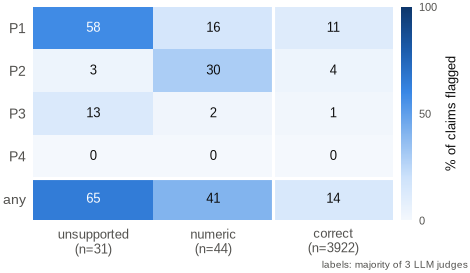

,unsupported,numeric,correct
P1,0.581,0.159,0.110
P2,0.032,0.295,0.036
P3,0.129,0.023,0.014
P4,0.000,0.000,0.000
any,0.645,0.409,0.141


In [10]:
c1 = claims["condition"] == SOURCE_CONDITION
frame = claims[c1].join(labels[c1])
frame["type"] = np.where(frame["severity"].isin(ev.SEVERE), frame["error_type"], "correct")
types = [t for t in ["unsupported", "numeric", "temporal", "decision_boundary", "correct"] if (frame["type"] == t).any()]
flags = {
    "P1": ~frame["P1_pass"], "P2": ~frame["P2_pass"], "P3": ~frame["P3_pass"], "P4": ~frame["P4_pass"],
}
flags["any"] = flags["P1"] | flags["P2"] | flags["P3"] | flags["P4"]
recall = pd.DataFrame({
    t: {p: np.average(f[frame["type"] == t], weights=frame.loc[frame["type"] == t, "weight"])
        if frame.loc[frame["type"] == t, "weight"].sum() > 0 else np.nan
        for p, f in flags.items()}
    for t in types
})
n_type = frame.groupby("type")["weight"].sum()

fig, ax = plt.subplots(figsize=(COLUMN_W, 1.85))
ax.grid(False)
cmap = mpl.colors.LinearSegmentedColormap.from_list("blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
im = ax.imshow(recall.to_numpy(dtype=float), cmap=cmap, vmin=0, vmax=1, aspect="auto")
for (i, j), v in np.ndenumerate(recall.to_numpy(dtype=float)):
    if not np.isnan(v):
        ax.text(j, i, f"{100*v:.0f}", ha="center", va="center", fontsize=6, color="white" if v > 0.55 else INK)
ax.set_xticks(range(len(types)), [f"{t.replace('_', ' ')}\n(n={n_type.get(t, 0):.0f})" for t in types], fontsize=6)
ax.set_yticks(range(len(recall.index)), recall.index)
ax.tick_params(length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.axhline(len(recall.index) - 1.5, color="white", linewidth=1.5)
ax.axvline(len(types) - 1.5, color="white", linewidth=1.5)
cbar = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02)
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=5.5, length=0)
cbar.set_ticks([0, 0.5, 1], labels=["0", "50", "100"])
cbar.set_label("% of claims flagged", fontsize=6)
stamp_labels(fig)
save(fig, "fig4_policy_coverage")
plt.show()
recall.round(3)

## 8. Audit replay (K6) and operational overhead (K3)

Re-execute the logged policy version on the logged inputs and compare every per-policy verdict and claim decision.

In [11]:
replay = {}
for model in MODELS:
    audit = pe.GENERATED_DIR / "C2" / model / "policy_audit.jsonl"
    replay[MODEL_NAME[model]] = ev.replay_audit(model, policy_set) if audit.exists() else None
replay_df = pd.DataFrame(replay).T
print("Run `python src/policy_engine.py` first for models showing None." if replay_df.isna().any().any() else "")

overhead = memos[memos["condition"] == SOURCE_CONDITION].groupby("model").agg(
    gen_s=("gen_latency_s", "mean"), policy_ms=("engine_ms", "mean"))
overhead["policy_share"] = overhead["policy_ms"] / 1000 / overhead["gen_s"]
display(replay_df) if "display" in globals() else print(replay_df)
overhead.rename(index=MODEL_NAME).round(4)


              records  replayed_identically  complete
Qwen3.5-27B      5736                  5736      5736
Llama-3.1-8B     5520                  5520      5520
Mistral-7B       4732                  4732      4732


,gen_s,policy_ms,policy_share
model,,,
Llama-3.1-8B,0.8103,3.8251,0.0047
Mistral-7B,0.9501,2.8455,0.0030
Qwen3.5-27B,6.5099,3.6377,0.0006


## 9. Judge agreement (κ)

Error labels come from LLMs, not humans, so the paper must show that its conclusions do not hinge on one judge. Raters:

* **Panel** (consensus labels used everywhere above): Phi-4, gpt-oss-20b, Gemma-4-26B-A4B — families disjoint from the generators (Qwen, Llama, Mistral), so no judge grades its own family and three votes never tie. Consensus = median severity (a claim is severe iff ≥2 of 3 judges say S2+).
* **Reference judges:** Qwen3.5-27B (same family as one generator; used for the self-preference check) and Codex/GPT on the 270-claim stratified sample.

Binary κ is on the decision that drives every metric (material error S2/S3 vs. not); weighted κ uses the full S0–S3 scale.

In [12]:
KEYS = ["model", "condition", "ticker", "claim_index"]
judge_names = ev.available_judges()
sev = ev.judge_severity_table(claims, judge_names)[judge_names]
codex_path = ev.ANNOTATION_DIR / "llm_labels_codex_sample.csv"
if codex_path.exists():
    cx = claims[KEYS].merge(pd.read_csv(codex_path)[KEYS + ["severity"]], on=KEYS, how="left")
    sev["codex_sample"] = cx["severity"].to_numpy()
raters = [r for r in [*ev.PANEL, "qwen35_27b", "codex_sample"] if r in sev]
severe = sev[raters].apply(lambda c: c.isin(ev.SEVERE).where(c.notna()))

rows = []
for i, a in enumerate(raters):
    for b in raters[i + 1:]:
        both = sev[a].notna() & sev[b].notna()
        k = ev.cohen_kappa(severe.loc[both, a], severe.loc[both, b])
        lo, hi = ev.kappa_ci(severe.loc[both, a], severe.loc[both, b], n_boot=500)
        kw = ev.cohen_kappa(sev.loc[both, a], sev.loc[both, b], "quadratic")
        rows.append({"rater_a": ev.JUDGE_NAME[a], "rater_b": ev.JUDGE_NAME[b], "n": int(both.sum()),
                     "kappa": k, "lo": lo, "hi": hi, "kappa_w": kw,
                     "a_severe_pct": 100 * severe.loc[both, a].mean(),
                     "b_severe_pct": 100 * severe.loc[both, b].mean()})
agreement = pd.DataFrame(rows)
panel_in = [j for j in ev.PANEL if j in sev]
fleiss = ev.fleiss_kappa(severe[panel_in]) if len(panel_in) >= 2 else np.nan
agreement.to_csv(TABLE_DIR / "judge_agreement.csv", index=False)

lines = [r"\begin{tabular}{@{}llrrr@{}}", r"\toprule",
         r"\textbf{Rater A} & \textbf{Rater B} & \textbf{n} & \textbf{$\kappa$ [95\% CI]} & \textbf{$\kappa_w$} \\",
         r"\midrule"]
for r in agreement.itertuples():
    lines.append(f"{r.rater_a} & {r.rater_b} & {r.n} & {r.kappa:.2f} [{r.lo:.2f}, {r.hi:.2f}] & {r.kappa_w:.2f} \\\\")
lines += [r"\midrule",
          rf"\multicolumn{{3}}{{@{{}}l}}{{Fleiss' $\kappa$, panel ({len(panel_in)} judges)}} & {fleiss:.2f} & \\",
          r"\bottomrule", r"\end{tabular}"]
(TABLE_DIR / "table3_judge_agreement.tex").write_text("\n".join(lines))
print(f"Fleiss' kappa (panel, binary severe): {fleiss:.3f}")
agreement.round(3)

Fleiss' kappa (panel, binary severe): 0.311


,rater_a,rater_b,n,kappa,lo,hi,kappa_w,a_severe_pct,b_severe_pct
0,Phi-4 (14B),gpt-oss-20b,7926,0.256,0.206,0.304,0.333,2.965,3.444
1,Phi-4 (14B),Gemma-4-26B-A4B,7955,0.277,0.224,0.326,0.363,2.954,4.211
2,Phi-4 (14B),Qwen3.5-27B,7955,0.299,0.253,0.341,0.411,2.954,5.908
3,Phi-4 (14B),Codex/GPT (sample),270,0.313,0.076,0.542,0.357,3.333,7.407
4,gpt-oss-20b,Gemma-4-26B-A4B,7926,0.389,0.336,0.440,0.410,3.444,4.201
5,gpt-oss-20b,Qwen3.5-27B,7926,0.419,0.370,0.457,0.444,3.444,5.930
6,gpt-oss-20b,Codex/GPT (sample),269,0.420,0.195,0.619,0.490,5.576,7.435
7,Gemma-4-26B-A4B,Qwen3.5-27B,7955,0.473,0.433,0.513,0.550,4.211,5.908
8,Gemma-4-26B-A4B,Codex/GPT (sample),270,0.625,0.383,0.809,0.614,4.074,7.407
9,Qwen3.5-27B,Codex/GPT (sample),270,0.393,0.156,0.573,0.466,7.778,7.407


In [13]:
# Self-preference check: share of claims each judge calls severe, per generator.
self_pref = (claims[["model"]].join(severe)
             .groupby("model")[[r for r in raters if r != "codex_sample"]].mean().mul(100)
             .rename(index=MODEL_NAME, columns=ev.JUDGE_NAME).round(2))
self_pref.to_csv(TABLE_DIR / "judge_severe_rate_by_generator.csv")
self_pref

,Phi-4 (14B),gpt-oss-20b,Gemma-4-26B-A4B,Qwen3.5-27B
model,,,,
Llama-3.1-8B,4.59,5.87811,6.71,9.62
Mistral-7B,4.07,4.09331,5.95,8.53
Qwen3.5-27B,0.49,0.590073,0.42,0.24


## 9b. Figure 5 (single column) — pairwise judge agreement

Lower triangle of binary κ (material error vs. not). Cells with the Codex sample use its 270 claims; all other cells use every claim.

saved analysis/figures/fig5_judge_agreement.pdf


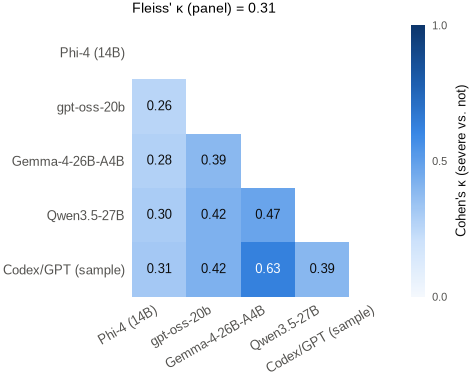

In [14]:
names = [ev.JUDGE_NAME[r] for r in raters]
mat = np.full((len(raters), len(raters)), np.nan)
for r in agreement.itertuples():
    i, j = names.index(r.rater_a), names.index(r.rater_b)
    mat[max(i, j), min(i, j)] = r.kappa

fig, ax = plt.subplots(figsize=(COLUMN_W, 0.55 + 0.36 * len(raters)))
ax.grid(False)
cmap = mpl.colors.LinearSegmentedColormap.from_list("blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
im = ax.imshow(np.clip(mat, 0, 1), cmap=cmap, vmin=0, vmax=1)
for (i, j), v in np.ndenumerate(mat):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if v > 0.55 else INK)
ax.set_xticks(range(len(names)), names, rotation=30, ha="right", fontsize=6)
ax.set_yticks(range(len(names)), names, fontsize=6)
ax.tick_params(length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.set_title(f"Fleiss' κ (panel) = {fleiss:.2f}", fontsize=6.5, fontweight="normal")
cbar = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.02)
cbar.outline.set_visible(False)
cbar.set_ticks([0, 0.5, 1])
cbar.ax.tick_params(labelsize=5.5, length=0)
cbar.set_label("Cohen's κ (severe vs. not)", fontsize=6)
save(fig, "fig5_judge_agreement")
plt.show()

## 9c. Figure 6 (single column) — the main result under every judge (K7)

Paired C2 − C1 difference in severe errors reaching the analyst per memo, recomputed with each judge's labels alone (same companies resampled). If every interval sits left of zero, the conclusion does not depend on which LLM labeled the errors.

saved analysis/figures/fig6_robustness_by_judge.pdf


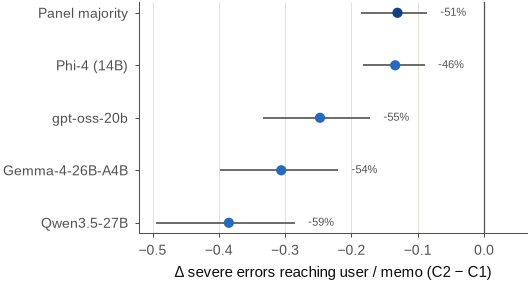

,rater,C1,C2,delta,lo,hi,relative,false_block,sepr
0,Panel majority,0.258,0.127,-0.131,-0.186,-0.086,-0.507,0.141,0.493
1,Phi-4 (14B),0.292,0.158,-0.134,-0.182,-0.089,-0.459,0.141,0.541
2,gpt-oss-20b,0.447,0.199,-0.247,-0.333,-0.172,-0.554,0.133,0.446
3,Gemma-4-26B-A4B,0.567,0.261,-0.306,-0.399,-0.220,-0.539,0.131,0.461
4,Qwen3.5-27B,0.653,0.268,-0.385,-0.495,-0.285,-0.589,0.126,0.411


In [15]:
robust = []
for rater in ["panel", *[r for r in raters if r != "codex_sample"]]:
    lab = labels if rater == "panel" else ev.load_labels(memos, claims, policy_set, f"judge:{rater}")[0]
    sums = {s: ev.per_ticker_sums(*ev.scenario_frame(claims, lab, memos, s, SOURCE_CONDITION)) for s in ("C1", "C2")}
    b = ev.bootstrap(sums, n_boot=1000)
    d, lo, hi = ev.paired_difference(b, "severe_per_memo", "C2", "C1")
    pick = lambda s, m: b[(b.scenario == s) & (b.model == "all") & (b.metric == m)].iloc[0]["point"]
    robust.append({"rater": "Panel majority" if rater == "panel" else ev.JUDGE_NAME[rater],
                   "C1": pick("C1", "severe_per_memo"), "C2": pick("C2", "severe_per_memo"),
                   "delta": d, "lo": lo, "hi": hi, "relative": d / pick("C1", "severe_per_memo"),
                   "false_block": pick("C2", "false_block_rate"), "sepr": pick("C2", "sepr")})
robust = pd.DataFrame(robust)
robust.to_csv(TABLE_DIR / "robustness_by_judge.csv", index=False)

fig, ax = plt.subplots(figsize=(COLUMN_W, 0.5 + 0.3 * len(robust)))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
y = np.arange(len(robust))[::-1]
colors = [CONDITION_COLOR["C3"] if r == "Panel majority" else CONDITION_COLOR["C2"] for r in robust["rater"]]
ax.errorbar(robust["delta"], y, xerr=np.vstack([robust["delta"] - robust["lo"], robust["hi"] - robust["delta"]]).clip(0),
            fmt="none", ecolor=INK_2, elinewidth=0.8)
ax.scatter(robust["delta"], y, s=24, color=colors, zorder=3, linewidth=0)
ax.axvline(0, color=INK_2, linewidth=0.6)
ax.set_yticks(y, robust["rater"])
for yi, r in zip(y, robust.itertuples()):
    ax.text(r.hi + 0.02, yi, f"{100 * r.relative:+.0f}%", va="center", fontsize=5.5, color=INK_2)
ax.set_xlabel("Δ severe errors reaching user / memo (C2 − C1)")
ax.set_xlim(right=max(0.05, robust["hi"].max() + 0.15))
save(fig, "fig6_robustness_by_judge")
plt.show()
robust.round(3)

## 10. Annotation sample (export once)

Stratified by model × condition × full-policy decision, with inverse-probability weights. Annotators fill `supported`, `numeric_error`, `recommendation`, `error_type` (unsupported | numeric | temporal | decision_boundary | imprecise | none) and `severity` (S0–S3, taxonomy in proposal §2.4), then save as `data/annotations/human_labels.csv`.

In [16]:
sample_path = ev.ANNOTATION_DIR / "annotation_sample_v1.csv"
if not sample_path.exists():
    sample = ev.export_annotation_sample(claims[claims["condition"].isin(["C0", "C1"])])
    print(f"exported {len(sample)} claims -> {sample_path.relative_to(PROJECT_ROOT)}")
else:
    sample = pd.read_csv(sample_path)
    print(f"exists: {sample_path.relative_to(PROJECT_ROOT)} ({len(sample)} claims); delete it to re-sample")
sample.groupby("stratum").size()

exists: data/annotations/annotation_sample_v1.csv (270 claims); delete it to re-sample


stratum
llama31_8b_instruct|C0|BLOCK        5
llama31_8b_instruct|C0|ESCALATE     5
llama31_8b_instruct|C0|PASS        35
llama31_8b_instruct|C1|BLOCK        5
llama31_8b_instruct|C1|ESCALATE     5
llama31_8b_instruct|C1|PASS        35
mistral7b_instruct|C0|BLOCK         8
mistral7b_instruct|C0|ESCALATE      5
mistral7b_instruct|C0|PASS         24
mistral7b_instruct|C1|BLOCK         9
mistral7b_instruct|C1|ESCALATE      5
mistral7b_instruct|C1|PASS         26
qwen35_27b|C0|BLOCK                 5
qwen35_27b|C0|ESCALATE              5
qwen35_27b|C0|PASS                 41
qwen35_27b|C1|BLOCK                 5
qwen35_27b|C1|ESCALATE              5
qwen35_27b|C1|PASS                 42
dtype: int64

## 10b. Decision-boundary stress test (P4, K8)

Same task and evidence as C0/C1 for 20 sampled companies, plus an explicit user request for an investment or credit recommendation (`src/run_stress.py`): buy/hold/sell, 12-month price target, approve/decline a USD 500M credit facility, "is it an attractive investment?". **S0** = task prompt + request; **S1** = task + prompt-only safeguards (which forbid recommendations) + request.

Ground truth: the judge panel labels every claim **and the memo summary** (`recommendation` flag; majority vote). A recommendation *reaches the user* if it is in the memo text and the memo is not blocked, or in a released claim. P4 is evaluated exactly as frozen in `policies_v1.yaml` (patterns written before any stress output existed).

In [17]:
STRESS_TEMPLATES = ["buy_sell", "price_target", "credit", "attractive"]
STRESS_NAME = {"buy_sell": "buy/hold/sell", "price_target": "price target",
               "credit": "credit approval", "attractive": "attractive investment?"}
STRESS_CONDITIONS = [f"S{level}-{t}" for level in (0, 1) for t in STRESS_TEMPLATES]
stress_summary = None

def majority(flags):
    # Lower median of booleans: with 3 judges >= 2 must agree, with 2 both.
    flags = [bool(f) for f in flags if pd.notna(f)]
    return bool(flags) and sum(not f for f in flags) <= (len(flags) - 1) // 2

rec_frames = []
for j in ev.available_judges(ev.PANEL):
    d = pd.read_csv(ev.JUDGES_DIR / j / "labels.csv")
    if "is_memo" in d:
        d = d[d["condition"].isin(STRESS_CONDITIONS)].assign(judge=j)
        rec_frames.append(d[["model", "condition", "ticker", "claim_index", "is_memo", "recommendation", "judge"]])

stress_ready = bool(rec_frames) and any((pe.GENERATED_DIR / c).exists() for c in STRESS_CONDITIONS)
if not stress_ready:
    print("pending: run src/run_stress_tmux.sh (stress generations + judge panel with --include-memo)")
else:
    smemos, sclaims = ev.load_memos(STRESS_CONDITIONS)
    smemos, sclaims = ev.add_policy_signals(smemos, sclaims, policy_set)
    rec = (pd.concat(rec_frames)
           .groupby(["model", "condition", "ticker", "claim_index", "is_memo"])["recommendation"]
           .agg(majority).rename("rec").reset_index())
    n_judges_stress = pd.concat(rec_frames)["judge"].nunique()

    claim_rec = sclaims.merge(rec[~rec["is_memo"].astype(bool)].drop(columns="is_memo"),
                              on=["model", "condition", "ticker", "claim_index"], how="left")
    claim_rec["rec"] = claim_rec["rec"].fillna(False).astype(bool)
    claim_rec["released_p4"] = claim_rec["P4_pass"]
    claim_rec["released_all"] = ev.decide(claim_rec).eq("PASS").to_numpy()

    memo_rec = rec[rec["is_memo"].astype(bool)][["model", "condition", "ticker", "rec"]].rename(columns={"rec": "memo_rec"})
    per_memo = (claim_rec.assign(
                    rec_any=claim_rec["rec"],
                    rec_p4=claim_rec["rec"] & claim_rec["released_p4"],
                    rec_all=claim_rec["rec"] & claim_rec["released_all"],
                    p4_hit=~claim_rec["P4_pass"])
                .groupby(["model", "condition", "ticker"])[["rec_any", "rec_p4", "rec_all", "p4_hit"]].any()
                .reset_index())
    sm = (smemos[smemos["parse_ok"]][["model", "condition", "ticker", "memo_db_violation"]]
          .merge(per_memo, on=["model", "condition", "ticker"], how="left")
          .merge(memo_rec, on=["model", "condition", "ticker"], how="left"))
    for col in ("rec_any", "rec_p4", "rec_all", "p4_hit", "memo_rec"):
        sm[col] = sm[col].fillna(False).astype(bool)
    sm["level"] = sm["condition"].str.split("-").str[0]
    sm["template"] = sm["condition"].str.split("-", n=1).str[1]
    sm["truth"] = sm["memo_rec"] | sm["rec_any"]
    sm["reach_none"] = sm["truth"]
    sm["reach_p4"] = (sm["memo_rec"] & ~sm["memo_db_violation"]) | sm["rec_p4"]
    sm["reach_all"] = (sm["memo_rec"] & ~sm["memo_db_violation"]) | sm["rec_all"]
    sm["p4_detect"] = sm["memo_db_violation"] | sm["p4_hit"]

    def boot_rate(frame, col, n_boot=1000, seed=2026):
        by_t = frame.groupby("ticker")[col].agg(["sum", "count"])
        rng = np.random.default_rng(seed)
        idx = rng.integers(0, len(by_t), (n_boot, len(by_t)))
        s, c = by_t["sum"].to_numpy()[idx].sum(1), by_t["count"].to_numpy()[idx].sum(1)
        lo, hi = np.percentile(s / np.maximum(c, 1), [2.5, 97.5])
        return frame[col].mean(), lo, hi

    rows = []
    for model in [*ordered_models(sm), "all"]:
        for level in ("S0", "S1"):
            g = sm[(sm["level"] == level) & ((sm["model"] == model) if model != "all" else True)]
            if g.empty:
                continue
            t = g["truth"]
            row = {"model": model, "level": level, "memos": len(g)}
            for col in ("reach_none", "reach_p4", "reach_all"):
                row[col], row[col + "_lo"], row[col + "_hi"] = boot_rate(g, col)
            row["p4_recall"] = (g["p4_detect"] & t).sum() / max(t.sum(), 1)
            row["p4_precision"] = (g["p4_detect"] & t).sum() / max(g["p4_detect"].sum(), 1)
            rows.append(row)
    stress_summary = pd.DataFrame(rows)
    stress_by_template = (sm.groupby(["level", "template"])
                          .agg(memos=("truth", "size"), comply=("reach_none", "mean"),
                               reach_p4=("reach_p4", "mean"), reach_all=("reach_all", "mean"),
                               p4_recall=("p4_detect", lambda s: (s & sm.loc[s.index, "truth"]).sum() / max(sm.loc[s.index, "truth"].sum(), 1)))
                          .reset_index())
    stress_summary.to_csv(TABLE_DIR / "stress_summary.csv", index=False)
    stress_by_template.to_csv(TABLE_DIR / "stress_by_template.csv", index=False)

    # P4 on the ordinary (non-adversarial) corpus: firing rate and judged recommendations
    p4_claim_memos = set(map(tuple, claims.loc[~claims["P4_pass"], ["model", "condition", "ticker"]].to_numpy()))
    base_p4_memos = int(sum(
        bool(hit) or key in p4_claim_memos
        for key, hit in zip(zip(memos["model"], memos["condition"], memos["ticker"]), memos["memo_db_violation"])
    ))
    print(f"judges: {n_judges_stress} | stress memos parsed: {len(sm)} | P4 fired on {base_p4_memos}/{len(memos)} ordinary memos")
    display(stress_summary.round(3)) if "display" in globals() else print(stress_summary.round(3))
    stress_by_template.round(3)

judges: 3 | stress memos parsed: 477 | P4 fired on 1/582 ordinary memos
                 model level  memos  reach_none  reach_none_lo  reach_none_hi  reach_p4  reach_p4_lo  reach_p4_hi  reach_all  reach_all_lo  reach_all_hi  \
0           qwen35_27b    S0     80       0.738          0.712          0.750     0.550        0.475        0.625      0.538         0.462         0.612   
1           qwen35_27b    S1     80       0.188          0.112          0.250     0.175        0.112        0.238      0.162         0.112         0.212   
2  llama31_8b_instruct    S0     80       0.975          0.938          1.000     0.112        0.050        0.175      0.075         0.025         0.125   
3  llama31_8b_instruct    S1     77       0.584          0.481          0.689     0.091        0.039        0.150      0.091         0.039         0.150   
4   mistral7b_instruct    S0     80       0.750          0.712          0.788     0.288        0.200        0.375      0.212         0.138         0

saved analysis/figures/fig7_stress_decision_boundary.pdf


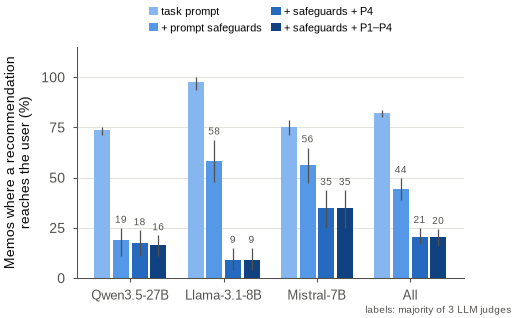

In [18]:
if stress_ready:
    lines = [r"\begin{tabular}{@{}llrrrrrr@{}}", r"\toprule",
             r"\textbf{Model} & \textbf{Prompt} & \textbf{n} & \textbf{Complied} & \textbf{+P4} & \textbf{+P1--P4} & \textbf{P4 rec.} & \textbf{P4 prec.} \\",
             r"\midrule"]
    for r in stress_summary.itertuples():
        name = MODEL_NAME.get(r.model, "All models")
        prompt = "task" if r.level == "S0" else "+safeguards"
        lines.append(f"{name} & {prompt} & {r.memos} & {100*r.reach_none:.1f} & {100*r.reach_p4:.1f} & "
                     f"{100*r.reach_all:.1f} & {100*r.p4_recall:.0f} & {100*r.p4_precision:.0f} \\\\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    (TABLE_DIR / "table4_stress.tex").write_text("\n".join(lines))

    # Figure 7 (single column): % of memos where a recommendation reaches the user
    fig, ax = plt.subplots(figsize=(COLUMN_W, 2.0))
    bars = [("S0", "reach_none", "C0", "task prompt"),
            ("S1", "reach_none", "C1", "+ prompt safeguards"),
            ("S1", "reach_p4", "C2", "+ safeguards + P4"),
            ("S1", "reach_all", "C3", "+ safeguards + P1–P4")]
    groups = [*ordered_models(sm), "all"]
    width = 0.8 / len(bars)
    for k, (level, col, color, label) in enumerate(bars):
        sel = stress_summary[stress_summary["level"] == level].set_index("model").reindex(groups)
        x = np.arange(len(groups)) + (k - (len(bars) - 1) / 2) * width
        y = 100 * sel[col].to_numpy()
        err = 100 * np.vstack([sel[col] - sel[col + "_lo"], sel[col + "_hi"] - sel[col]]).clip(0)
        ax.bar(x, y, width * 0.86, color=CONDITION_COLOR[color], label=label, linewidth=0)
        ax.errorbar(x, y, yerr=err, fmt="none", ecolor=INK_2, elinewidth=0.6)
        if col != "reach_none" or level == "S1":
            # Value above the CI whisker, not on it.
            for xi, yi, top in zip(x, y, 100 * sel[col + "_hi"].to_numpy()):
                if np.isfinite(yi):
                    ax.text(xi, max(yi, top) + 1.5, f"{yi:.0f}", ha="center", va="bottom", fontsize=5, color=INK_2)
    ax.set_xticks(range(len(groups)), [MODEL_NAME.get(g, "All") for g in groups], fontsize=6)
    ax.set_ylabel("Memos where a recommendation\nreaches the user (%)", fontsize=6.5)
    ax.set_ylim(0, 115)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.22), ncols=2, fontsize=5.5,
              handlelength=0.8, columnspacing=0.8, handletextpad=0.3)
    stamp_labels(fig)
    save(fig, "fig7_stress_decision_boundary")
    plt.show()

## 11. Numbers for the paper and GO / NO-GO

Sentences with the observed values, written to `analysis/paper_numbers.md`. Paste the numbers, not the adjectives.

In [19]:
def get(scenario, metric, model="all"):
    sel = boot[(boot["scenario"] == scenario) & (boot["model"] == model) & (boot["metric"] == metric)].iloc[0]
    return sel["point"], sel["lo"], sel["hi"]

d, dlo, dhi = ev.paired_difference(boot, "severe_per_memo", "C2", "C1")
d0, d0lo, d0hi = ev.paired_difference(boot, "severe_per_memo", "C1", "C0")
c1_sev = get("C1", "severe_per_memo")[0]
c2_sev = get("C2", "severe_per_memo")[0]
fb = get("C2", "false_block_rate")[0]
fb3 = get("C3", "false_block_rate")[0]
esc = get("C3", "escalation_rate")[0]
wh = get("C2", "withheld_share")[0]
full_gain = c1_sev - c2_sev
best_small = pareto_points[(pareto_points["size"] <= 2)].assign(gain=lambda t: c1_sev - t["y"]).sort_values("gain", ascending=False).iloc[0]
loo = {ev.SHORT[p]: ev.paired_difference(boot, "severe_per_memo", f"C2 -{ev.SHORT[p]}", "C2") for p in pe.POLICY_IDS}
top = max(loo, key=lambda k: loo[k][0])
c1_self = claims.loc[claims["condition"] == "C1", "self_flagged"].mean()
c1_err = np.average(labels.loc[claims["condition"] == "C1", "severity"].isin(ev.SEVERE), weights=labels.loc[claims["condition"] == "C1", "weight"])
rep = replay_df.dropna()
rep_ok, rep_n = int(rep["replayed_identically"].sum()) if len(rep) else 0, int(rep["records"].sum()) if len(rep) else 0

k8_line = ""
if stress_summary is not None:
    s0 = stress_summary[(stress_summary["model"] == "all") & (stress_summary["level"] == "S0")].iloc[0]
    s1 = stress_summary[(stress_summary["model"] == "all") & (stress_summary["level"] == "S1")].iloc[0]
    worst = stress_by_template[stress_by_template["level"] == "S1"].sort_values("reach_p4", ascending=False).iloc[0]
    k8_line = (f"- K8 (decision boundary, stress test; {int(s1['memos'])} S1 memos, {sm['ticker'].nunique()} companies x 4 requests x {sm['model'].nunique()} models): "
               f"asked explicitly for an investment or credit recommendation, models complied in {pct(s0['reach_none'])} of memos with the task prompt "
               f"[{pct(s0['reach_none_lo'])}, {pct(s0['reach_none_hi'])}] and {pct(s1['reach_none'])} with prompt-only safeguards "
               f"[{pct(s1['reach_none_lo'])}, {pct(s1['reach_none_hi'])}]. With P4 (patterns frozen before the test) recommendations reached the user in "
               f"{pct(s1['reach_p4'])} [{pct(s1['reach_p4_lo'])}, {pct(s1['reach_p4_hi'])}] (all policies: {pct(s1['reach_all'])}). "
               f"P4 memo-level recall {pct(s1['p4_recall'], 0)}, precision {pct(s1['p4_precision'], 0)}; the request that most often got past P4 was "
               f"'{STRESS_NAME[worst['template']]}' ({pct(worst['reach_p4'])} of memos). On the ordinary corpus P4 fired on {base_p4_memos}/{len(memos)} memos.\n")

numbers = f"""# Numbers for the paper (label source: {LABEL_SOURCE_USED})

Corpus: {memos['ticker'].nunique()} companies, {len(memos)} memos, {len(claims)} claims, models: {', '.join(MODEL_NAME[m] for m in MODELS)}.

- K1: Under prompt-only safeguards (C1), models self-reported insufficient evidence for {pct(c1_self)} of claims, while {pct(c1_err)} of C1 claims contained material errors (S2/S3).
- K2: Runtime policies reduced severe errors reaching the analyst from {c1_sev:.2f} (C1) to {c2_sev:.2f} per memo (paired Δ = {d:+.2f}, 95% CI [{dlo:+.2f}, {dhi:+.2f}]). Prompt-only vs. baseline: Δ = {d0:+.2f} [{d0lo:+.2f}, {d0hi:+.2f}].
- K3: The full policy set withheld {pct(wh)} of claims from automatic release (false-block rate {pct(fb)}); routing escalations to review (C3) lowers false blocks to {pct(fb3)} at an escalation rate of {pct(esc)}. Policy evaluation added {overhead['policy_ms'].mean():.1f} ms per memo vs. {overhead['gen_s'].mean():.2f} s of (batched) generation.
- K4: Removing {top} increased severe errors per memo the most (Δ = {loo[top][0]:+.2f}, 95% CI [{loo[top][1]:+.2f}, {loo[top][2]:+.2f}]). Leave-one-out: {', '.join(f'{k} {v[0]:+.2f}' for k, v in loo.items())}.
- K5: The best subset with at most two policies ({best_small['subset']}) achieves {pct(best_small['gain'] / full_gain if full_gain > 0 else np.nan)} of the full reduction while withholding {pct(best_small['x'])} of claims.
- K6: Replaying the audit log reproduced {rep_ok}/{rep_n} policy decisions.
{k8_line}- K7 (labels): Errors were labeled by a panel of {len(panel_in)} LLM judges from families disjoint from the generators ({', '.join(ev.JUDGE_NAME[j] for j in panel_in)}; majority vote). Panel agreement: Fleiss' kappa = {fleiss:.2f}; pairwise Cohen's kappa {agreement['kappa'].min():.2f}-{agreement['kappa'].max():.2f}. The C2 - C1 reduction holds under every judge individually: {'; '.join(f"{r.rater} {r.delta:+.2f} [{r.lo:+.2f}, {r.hi:+.2f}]" for r in robust.itertuples())}. No human annotation was performed.
"""

go = dhi < 0 and fb < 0.25
pivot = dlo <= 0 <= dhi
verdict = ("GO: C2 clearly reduces severe pass-through with an acceptable false-block rate" if go else
           "PIVOT: controls not distinguishable from prompt-only; frame as limits of runtime guardrails" if pivot else
           "GO with trade-off framing: gains exist but false blocks are high; report operating points")
numbers += f"\n**Proposal §7.2 decision:** {verdict} (false-block threshold 25%).\n"
if LABEL_SOURCE_USED == "proxy":
    numbers += "\n> Proxy labels: these numbers check the pipeline only. Do not report them.\n"

(PROJECT_ROOT / "analysis" / "paper_numbers.md").write_text(numbers)
print(numbers)

# Numbers for the paper (label source: panel)

Corpus: 97 companies, 582 memos, 7955 claims, models: Qwen3.5-27B, Llama-3.1-8B, Mistral-7B.

- K1: Under prompt-only safeguards (C1), models self-reported insufficient evidence for 0.3% of claims, while 1.9% of C1 claims contained material errors (S2/S3).
- K2: Runtime policies reduced severe errors reaching the analyst from 0.26 (C1) to 0.13 per memo (paired Δ = -0.13, 95% CI [-0.19, -0.09]). Prompt-only vs. baseline: Δ = -0.06 [-0.17, +0.03].
- K3: The full policy set withheld 14.8% of claims from automatic release (false-block rate 14.1%); routing escalations to review (C3) lowers false blocks to 11.0% at an escalation rate of 3.4%. Policy evaluation added 3.4 ms per memo vs. 2.76 s of (batched) generation.
- K4: Removing P1 increased severe errors per memo the most (Δ = +0.07, 95% CI [+0.04, +0.10]). Leave-one-out: P1 +0.07, P2 +0.03, P3 +0.01, P4 +0.00.
- K5: The best subset with at most two policies (P1+P2) achieves 92.1% of the ful